# EN3160 Assignment 2 — Fitting and Alignment

**Name:** Heshan Ranasinghe  
**Index:** 230521E  
**GitHub profile:** https://github.com/DPHeshanRanasinghe/EN3160-Image-Processing-and-Machine-Vision

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = Path("images")

if not IMAGE_DIR.is_dir():
    IMAGE_DIR = Path("Assignment_02") / "images"

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Cannot find the Assignment_02 images folder.\n"
        f"Current working folder: {Path.cwd()}"
    )

required_images = [
    "the_berry_farms_sunflower_field.jpeg",
    "wadham.jpg",
    "flag.png",
    "pcbs/AAAA1.jpg",
    "pcbs/ADAD1.jpg",
    "pcbs/AECC1.jpg",
    "pcbs/AECC2.jpg",
    "pcbs/AECC3.jpg",
    "pcbs/AECC4.jpg",
]


missing = [
    name for name in required_images
    if not (IMAGE_DIR / name).is_file()
]

if missing:
    raise FileNotFoundError(f"Missing images: {missing}")

print("Image folder:", IMAGE_DIR.resolve())
print("All required images are available.")

Image folder: D:\3_Semester 5\Image Processing & Machine Vision\github\Assignment_02\images
All required images are available.


## Question 1 - Sunflower candidates using LoG

I loaded the sunflower image using `cv2.IMREAD_REDUCED_COLOR_4`, so the image used for detection is 360 x 360 pixels. I used Laplacian of Gaussian (LoG) responses at many sigma values to find dark, round flower-centre candidates.

For each candidate, the radius is estimated by $R \approx \sqrt{2}\,\sigma$. The reported row, column, sigma and radius values are in pixels of the reduced image. LoG alone also responds to clouds, leaves and tree regions, so I added a simple colour check to keep candidates that have yellow petals around the dark centre. This colour check is only a verification step; it is not part of pure LoG theory.

The figure compares the original absolute-LoG detector, signed dark-centre LoG, and the final signed LoG with the petal check.


**Key code.**

```python
gray = q1_gray.astype(float) / 255.0
sigmas = np.geomspace(1, 32, 41)

log_space = np.stack([
    sigma**2 * signed_log_response(gray, sigma)
    for sigma in sigmas
])

peaks = log_space == maximum_filter(log_space, size=(3, 3, 3))
radius = np.sqrt(2) * sigma

# Keep local scale-space peaks, then verify yellow petals
# around the dark-centre LoG candidates.
```

Reduced image: 360 x 360 pixels; all measurements below use it.
Computed sigma range: 1-32 px (41 geometric samples, ratio 1.0905).
Eligible sigma: radius >= 2.5 px and sigma <= 20 px; endpoints are guards.
Original absolute LoG: t=0.08 -> 187; t=0.12 -> 135 candidates.
Signed LoG alone: 298; with petal check: t=0.08 -> 56, t=0.12 -> 54 candidates.
Retained sigma range: 1.834-7.336 px.


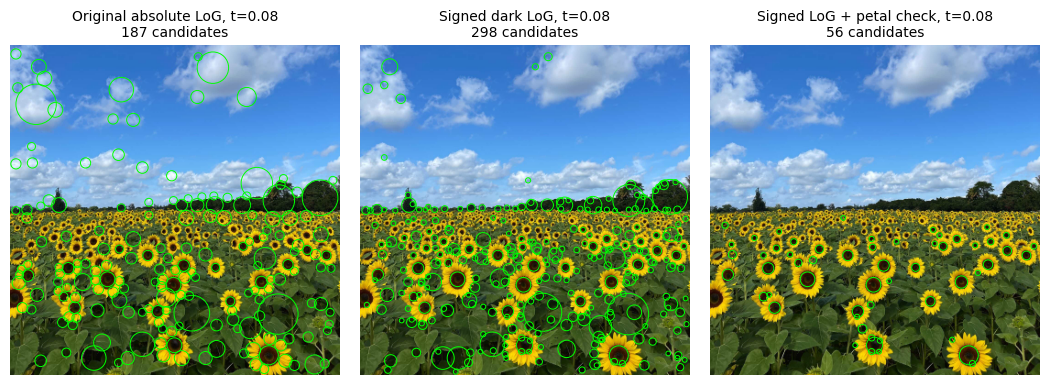

**Largest retained flower-centre candidates**

| x = row | y = column | sigma (px) | radius (px) | LoG response |
|---:|---:|---:|---:|---:|
| 338 | 282 | 7.336 | 10.375 | 0.3491 |
| 327 | 179 | 6.169 | 8.724 | 0.3447 |
| 255 | 106 | 5.657 | 8.000 | 0.3617 |
| 261 | 178 | 5.657 | 8.000 | 0.3527 |
| 258 | 274 | 4.757 | 6.727 | 0.3448 |


In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import gaussian_laplace, maximum_filter
from IPython.display import display, Markdown

q1_path = Path('images/the_berry_farms_sunflower_field.jpeg')
if not q1_path.is_file():
    q1_path = Path('Assignment_02') / q1_path
q1_bgr = cv2.imread(str(q1_path), cv2.IMREAD_REDUCED_COLOR_4)
if q1_bgr is None:
    raise FileNotFoundError(q1_path)
q1_rgb = cv2.cvtColor(q1_bgr, cv2.COLOR_BGR2RGB)
q1_gray = cv2.cvtColor(q1_bgr, cv2.COLOR_BGR2GRAY).astype(float) / 255
q1_colour = q1_rgb.astype(float) / 255
q1_yellow = np.maximum(np.minimum(q1_colour[..., 0], q1_colour[..., 1])
                       - q1_colour[..., 2], 0)
q1_height, q1_width = q1_gray.shape

# Eight samples per octave; the endpoints are guard scales, not detections.
q1_sigmas = np.geomspace(1, 32, 41)
q1_response = np.stack([
    s**2 * gaussian_laplace(q1_gray, s, mode='reflect') for s in q1_sigmas
])  # Positive LoG selects dark centres; negative LoG selects bright blobs.

def q1_peak_indices(response, threshold, strict_scale=True):
    # Explicit 26-neighbour comparison in (scale, row, column).
    peaks = response == maximum_filter(response, size=(3, 3, 3),
                                       mode='constant', cval=-np.inf)
    peaks[[0, -1]] = False
    if strict_scale:  # Reject flat scale plateaus rather than duplicating them.
        peaks[1:-1] &= ((response[1:-1] > response[:-2]) &
                       (response[1:-1] > response[2:]))
    indices = np.argwhere(peaks & (response > threshold))
    order = np.argsort(-response[tuple(indices.T)], kind='stable')
    return indices[order]

def q1_petal_check(row, col, radius):
    # Verify colour around a LoG peak; do not generate or move its centre.
    a, b = max(0, int(row-2*radius)), min(q1_height, int(row+2*radius)+1)
    c, d = max(0, int(col-2*radius)), min(q1_width, int(col+2*radius)+1)
    rr, cc = np.ogrid[a:b, c:d]
    dr, dc = rr-row, cc-col
    distance = np.hypot(dr, dc)
    core = distance <= 0.65*radius
    ring = (distance >= 1.05*radius) & (distance <= 1.9*radius)
    yellow = q1_yellow[a:b, c:d]
    rgb = q1_colour[a:b, c:d]
    # Yellow must surround several sides, not just one neighbouring flower.
    sectors = np.floor((np.arctan2(dr, dc)+np.pi)*4/np.pi).astype(int) % 8
    supported = 0
    for sector in range(8):
        pixels = ring & (sectors == sector)
        supported += pixels.any() and np.mean(yellow[pixels] > 0.22) >= 0.15
    return (np.mean(yellow[ring] > 0.22) >= 0.30
            and yellow[ring].mean()-yellow[core].mean() >= 0.08
            and (rgb[..., 0][core].mean()-rgb[..., 1][core].mean()) >= -0.04
            and supported >= 5)

def q1_select(response, sigmas, threshold, verify=False, old_rule=False):
    selected = []
    for k, row, col in q1_peak_indices(response, threshold,
                                      strict_scale=not old_rule):
        sigma = sigmas[k]
        radius = np.sqrt(2)*sigma
        if radius < (4 if old_rule else 2.5):
            continue
        if not old_rule and sigma > 20:  # Larger computed scales are guards.
            continue
        if not (radius <= row < q1_height-radius and
                radius <= col < q1_width-radius):
            continue  # Incomplete dark disks are not reported.
        if verify and not q1_petal_check(row, col, radius):
            continue  # Reject background before it can suppress a flower.
        duplicate = any(
            np.hypot(row-v[0], col-v[1]) <
            (0.7*(radius+v[3]) if old_rule else 0.6*min(radius, v[3]))
            for v in selected
        )
        if not duplicate:
            selected.append((row, col, sigma, radius, response[k, row, col]))
    return np.asarray(selected, dtype=float).reshape(-1, 5)

# Reproduce the original method so the comparison uses the same image.
q1_original_sigmas = np.geomspace(1, 20, 25)
q1_original_response = np.stack([
    s**2 * np.abs(gaussian_laplace(q1_gray, s, mode='reflect'))
    for s in q1_original_sigmas
])
q1_original = {t: q1_select(q1_original_response, q1_original_sigmas, t,
                           old_rule=True) for t in (0.08, 0.12)}
q1_dark_only = q1_select(q1_response, q1_sigmas, 0.08)
q1_final = q1_select(q1_response, q1_sigmas, 0.08, verify=True)
q1_final_high = q1_select(q1_response, q1_sigmas, 0.12, verify=True)

print(f'Reduced image: {q1_width} x {q1_height} pixels; all measurements below use it.')
print('Computed sigma range: 1-32 px (41 geometric samples, ratio 1.0905).')
print('Eligible sigma: radius >= 2.5 px and sigma <= 20 px; endpoints are guards.')
print(f'Original absolute LoG: t=0.08 -> {len(q1_original[0.08])}; '
      f't=0.12 -> {len(q1_original[0.12])} candidates.')
print(f'Signed LoG alone: {len(q1_dark_only)}; with petal check: '
      f't=0.08 -> {len(q1_final)}, t=0.12 -> {len(q1_final_high)} candidates.')
if len(q1_final):
    print(f'Retained sigma range: {q1_final[:, 2].min():.3f}-'
          f'{q1_final[:, 2].max():.3f} px.')

q1_fig, q1_axes = plt.subplots(1, 3, figsize=(10.5, 3.7),
                               constrained_layout=True)
q1_panels = [('Original absolute LoG, t=0.08', q1_original[0.08]),
             ('Signed dark LoG, t=0.08', q1_dark_only),
             ('Signed LoG + petal check, t=0.08', q1_final)]
for ax, (title, candidates) in zip(q1_axes, q1_panels):
    ax.imshow(q1_rgb)
    for row, col, sigma, radius, score in candidates:
        ax.add_patch(Circle((col, row), radius, fill=False,
                            edgecolor='lime', linewidth=0.7))
    ax.set_title(f'{title}\n{len(candidates)} candidates', fontsize=10)
    ax.axis('off')
plt.show()

# Largest by radius, with response strength as a deterministic tie-breaker.
q1_largest = q1_final[np.lexsort((-q1_final[:, 4], -q1_final[:, 3]))][:5]
q1_table = '| x = row | y = column | sigma (px) | radius (px) | LoG response |\n'
q1_table += '|---:|---:|---:|---:|---:|\n'
for row, col, sigma, radius, score in q1_largest:
    q1_table += f'| {row:.0f} | {col:.0f} | {sigma:.3f} | {radius:.3f} | {score:.4f} |\n'
display(Markdown('**Largest retained flower-centre candidates**\n\n'+q1_table))


### Interpretation and discussion

The original absolute-LoG method found many candidates, but it also marked clouds, trees and leaves. This happened because it accepted strong responses of both signs. The signed dark-centre LoG was closer to the sunflower-centre idea, but it still found many dark background structures.

The final method kept only dark-centre candidates that also had yellow evidence around them. This reduced the result to 56 candidates and removed many obvious false detections. I used 41 sigma values from 1 to 32 pixels, with larger values acting as guard scales. The accepted detections used sigma values up to 20 pixels and radii of at least 2.5 pixels.

The retained sigma range was 1.834-7.336 pixels, and the largest estimated centre radius was 10.375 pixels. These circles show dark flower centres, not the full flower heads. Some small or hidden flowers are still missed, and some small candidates may still be uncertain, so the count is a candidate count, not an exact sunflower count.


## Question 2 - Line and circle fitting with RANSAC

The data has two shapes mixed together: one noisy line and one noisy circle. I generated the data from Listing 1 using seed 0. During fitting, the code does not use the true labels; it only sees the combined point set.

RANSAC is useful here because a normal least-squares fit would be affected by points from the other shape. For the line, two random points form a hypothesis $ax + by = d$, where $a^2 + b^2 = 1$. This makes $|ax_i + by_i - d|$ the perpendicular distance. For the circle, three non-collinear points form a hypothesis, and the inlier error is the radial error.

I first fit the line, remove its inliers, and then fit the circle to the remaining points. I also run the opposite order to see what changes.


**Key code.**

```python
# Line model: ax + by = d, with a^2 + b^2 = 1
line_error = np.abs(points @ model[:2] - model[2])

# Circle radial error
circle_error = np.abs(np.linalg.norm(points - centre, axis=1) - radius)

# Key code showing my own RANSAC loop.

python
def q2_ransac(points, kind, threshold, minimum, iterations, seed):
    rng = np.random.default_rng(seed)
    best, best_key = None, None

    for _ in range(iterations):
        sample = rng.choice(len(points), size, replace=False)
        model = hypothesis(points[sample])
        if model is None:
            continue

        residual = q2_errors(points, model, kind)
        mask = residual <= threshold
        count = int(mask.sum())

        if count >= minimum:
            key = (count, -np.mean(residual[mask]**2))
            if best_key is None or key > best_key:
                best_key = key
                best = dict(sample=sample, hypothesis=model,
                            hypothesis_mask=mask)

# Refit the final model using all selected inliers.
```

In [3]:
import numpy as np
from scipy.optimize import least_squares

def q2_line_sign(model):
    normal, d = np.asarray(model[:2], float), float(model[2])
    if d < 0 or (d == 0 and normal[np.argmax(np.abs(normal))] < 0):
        normal, d = -normal, -d
    return np.r_[normal, d]  # ax + by = d; unit normal, unsigned d.

def q2_line_sample(points):
    delta = points[1]-points[0]
    length = np.linalg.norm(delta)
    if length <= 1e-10:
        return None
    normal = np.array([-delta[1], delta[0]])/length
    return q2_line_sign(np.r_[normal, normal @ points[0]])

def q2_circle_sample(points):
    u, v = points[1]-points[0], points[2]-points[0]
    lengths = np.linalg.norm(u)*np.linalg.norm(v)
    area = abs(u[0]*v[1]-u[1]*v[0])
    if lengths <= 1e-10 or area/lengths < 1e-3:
        return None  # Duplicate or nearly collinear points (small sine angle).
    try:
        offset = np.linalg.solve(2*np.vstack([u, v]), [u @ u, v @ v])
    except np.linalg.LinAlgError:
        return None
    model = np.r_[points[0]+offset, np.linalg.norm(offset)]
    return model if np.isfinite(model).all() and model[2] > 1e-9 else None

def q2_errors(points, model, kind):
    if kind == 'line':
        return np.abs(points @ model[:2]-model[2])  # Unit-normal distance.
    return np.abs(np.linalg.norm(points-model[:2], axis=1)-model[2])

def q2_refit(points, initial, kind):
    if kind == 'line':
        mean = points.mean(axis=0)
        _, _, vt = np.linalg.svd(points-mean, full_matrices=False)
        normal = vt[-1]
        return q2_line_sign(np.r_[normal, normal @ mean])
    # Minimize squared radial residuals; the radius is bounded only away from 0.
    result = least_squares(
        lambda p: np.linalg.norm(points-p[:2], axis=1)-p[2], initial,
        bounds=([-np.inf, -np.inf, 1e-9], [np.inf, np.inf, np.inf]),
        ftol=1e-10, xtol=1e-10, gtol=1e-10, max_nfev=2000)
    if not result.success or not np.isfinite(result.x).all():
        raise RuntimeError('Circle refit did not converge.')
    return result.x

def q2_ransac(points, kind, threshold, minimum, iterations, seed):
    points = np.asarray(points, float)
    size = 2 if kind == 'line' else 3
    if len(points) < max(size, minimum):
        raise ValueError(f'Not enough points for the {kind} consensus.')
    rng = np.random.default_rng(seed)
    hypothesis = q2_line_sample if kind == 'line' else q2_circle_sample
    best, best_key, skipped = None, None, 0
    for _ in range(iterations):
        sample = rng.choice(len(points), size=size, replace=False)
        model = hypothesis(points[sample])
        if model is None:
            skipped += 1
            continue
        residual = q2_errors(points, model, kind)
        mask = residual <= threshold
        count = int(mask.sum())
        if count < minimum:
            continue
        key = (count, -np.mean(residual[mask]**2))
        if best_key is None or key > best_key:
            best_key = key
            best = dict(sample=sample.copy(), hypothesis=model.copy(),
                        hypothesis_mask=mask.copy())
    if best is None:
        raise RuntimeError(f'No valid {kind} consensus of {minimum} points.')
    # Refit and reclassify until the reported model and membership agree.
    model, mask = best['hypothesis'].copy(), best['hypothesis_mask'].copy()
    for step in range(30):
        model = q2_refit(points[mask], model, kind)
        residual = q2_errors(points, model, kind)
        new_mask = residual <= threshold
        if new_mask.sum() < minimum:
            raise RuntimeError(f'{kind} consensus fell below its minimum.')
        if np.array_equal(mask, new_mask):
            break
        mask = new_mask
    else:
        raise RuntimeError(f'{kind} refit membership did not stabilize.')
    best.update(model=model, mask=new_mask, residual=residual,
                rmse=float(np.sqrt(np.mean(residual[new_mask]**2))),
                refits=step+1, skipped=skipped, threshold=threshold,
                minimum=minimum, iterations=iterations, seed=seed)
    return best

def q2_generate(seed=0):
    # Listing 1's draw order and legacy generator are kept for reproducibility.
    rng = np.random.RandomState(seed)
    theta = rng.uniform(0, 2*np.pi, 50)
    radial_noise = (10/16)*rng.randn(50)
    circle = np.column_stack([2+(10+radial_noise)*np.cos(theta),
                              3+(10+radial_noise)*np.sin(theta)])
    x = np.linspace(-12, 12, 50)
    line = np.column_stack([x, -x+2+rng.randn(50)])
    return np.vstack([circle, line])

q2_X = q2_generate(0)
q2_settings = {'line': dict(threshold=1.5, minimum=35, iterations=1000, seed=101),
               'circle': dict(threshold=1.25, minimum=30, iterations=2000, seed=202)}

def q2_fit_order(points, first):
    second = 'circle' if first == 'line' else 'line'
    first_fit = q2_ransac(points, first, **q2_settings[first])
    remaining = np.flatnonzero(~first_fit['mask'])
    try:
        second_fit = q2_ransac(points[remaining], second, **q2_settings[second])
    except (RuntimeError, ValueError) as error:
        second_fit = None
        failure = str(error)
    else:
        failure = None
    return dict(first=first, fits={first:first_fit, second:second_fit},
                remaining=remaining, failure=failure)


Listing 1: 50 circle + 50 line points; data seed 0 (RandomState).
Line: perpendicular threshold 1.50, minimum 35, 1000 trials, sample seed 101.
Circle: radial threshold 1.25, minimum 30, 2000 trials, sample seed 202.
RMSE = sqrt(mean(squared geometric residual)) over the FINAL consensus.


| Order | Model | Final parameters | Inliers / fitted points | RMSE |
|---|---|---|---:|---:|
| Line first | line | a=0.72096, b=0.69297, d=1.57242 | 54 / 100 | 0.67058 |
| Line first | circle | centre=(1.89823, 3.01007), r=9.83141 | 44 / 46 | 0.53105 |
| Circle first | circle | centre=(1.90202, 3.01760), r=9.88018 | 57 / 100 | 0.57133 |
| Circle first | line | a=0.72316, b=0.69068, d=1.66384 | 41 / 43 | 0.58869 |


Line-first winning samples and ORIGINAL hypotheses (zero-based X indices):
line: sample [96, 56], hypothesis [0.7022, 0.71198, 1.60293], sample-consensus 56 -> final 54
circle: sample [14, 12, 27], hypothesis [2.02656, 3.01307, 10.01197], sample-consensus 46 -> final 44
After-fitting label check (generated circle points / generated line points):
Line first, line: 4 / 50
Line first, circle: 44 / 0
Circle first, circle: 48 / 9
Circle first, line: 0 / 41
Large-radius diagnostic: r=591.249, 53 inliers (3 generated circle / 50 generated line). This hypothesis did not win.


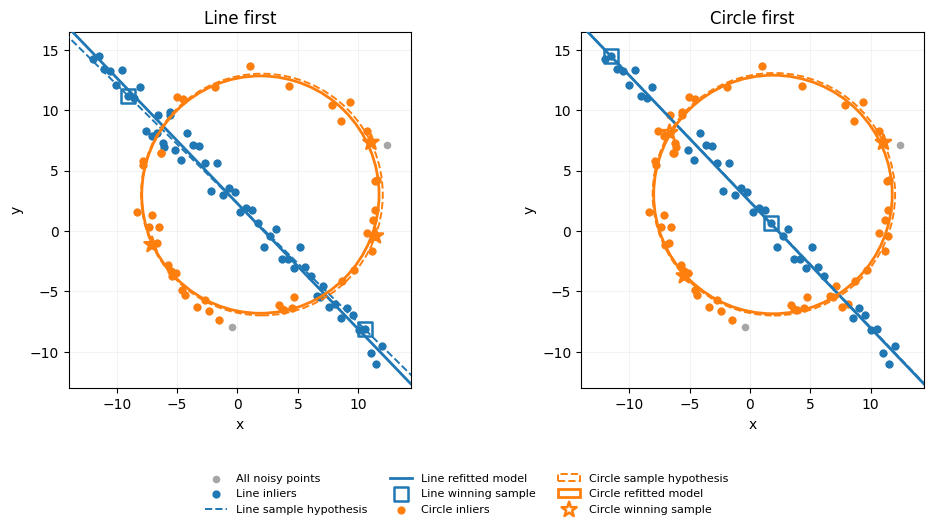

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import display, Markdown

q2_line_first = q2_fit_order(q2_X, 'line')
q2_circle_first = q2_fit_order(q2_X, 'circle')
q2_runs = [('Line first', q2_line_first), ('Circle first', q2_circle_first)]

def q2_global_indices(run, kind):
    return np.arange(len(q2_X)) if kind == run['first'] else run['remaining']

print('Listing 1: 50 circle + 50 line points; data seed 0 (RandomState).')
print('Line: perpendicular threshold 1.50, minimum 35, 1000 trials, sample seed 101.')
print('Circle: radial threshold 1.25, minimum 30, 2000 trials, sample seed 202.')
print('RMSE = sqrt(mean(squared geometric residual)) over the FINAL consensus.')

q2_table = '| Order | Model | Final parameters | Inliers / fitted points | RMSE |\n'
q2_table += '|---|---|---|---:|---:|\n'
for order, run in q2_runs:
    for kind in (run['first'], 'circle' if run['first']=='line' else 'line'):
        fit = run['fits'][kind]
        if fit is None:
            q2_table += f'| {order} | {kind} | No valid consensus | — | — |\n'
            continue
        ids = q2_global_indices(run, kind)
        a, b, c = fit['model']
        parameters = (f'a={a:.5f}, b={b:.5f}, d={c:.5f}' if kind=='line'
                      else f'centre=({a:.5f}, {b:.5f}), r={c:.5f}')
        q2_table += (f'| {order} | {kind} | {parameters} | '
                     f'{fit["mask"].sum()} / {len(ids)} | {fit["rmse"]:.5f} |\n')
display(Markdown(q2_table))

print('Line-first winning samples and ORIGINAL hypotheses (zero-based X indices):')
for kind in ('line', 'circle'):
    fit = q2_line_first['fits'][kind]
    print(f'{kind}: sample {q2_global_indices(q2_line_first, kind)[fit["sample"]].tolist()}, '
          f'hypothesis {np.round(fit["hypothesis"], 5).tolist()}, '
          f'sample-consensus {fit["hypothesis_mask"].sum()} -> final {fit["mask"].sum()}')

# Evaluation only: generating labels NEVER enter any fitting function.
print('After-fitting label check (generated circle points / generated line points):')
for order, run in q2_runs:
    for kind, fit in run['fits'].items():
        if fit is not None:
            ids = q2_global_indices(run, kind)[fit['mask']]
            print(f'{order}, {kind}: {np.sum(ids < 50)} / {np.sum(ids >= 50)}')
    if run['failure']:
        print(f'{order}: {run["failure"]}')

# Same circle-first sample sequence: audit broad circles, without restricting them.
q2_rng = np.random.default_rng(q2_settings['circle']['seed'])
q2_span = np.linalg.norm(np.ptp(q2_X, axis=0))
q2_broad = None
for _ in range(q2_settings['circle']['iterations']):
    sample = q2_rng.choice(len(q2_X), 3, replace=False)
    model = q2_circle_sample(q2_X[sample])
    if model is not None and model[2] > 5*q2_span:
        mask = q2_errors(q2_X, model, 'circle') <= q2_settings['circle']['threshold']
        if q2_broad is None or mask.sum() > q2_broad['mask'].sum():
            q2_broad = dict(model=model, mask=mask)
if q2_broad is not None:
    ids = np.flatnonzero(q2_broad['mask'])  # Labels used only after this selection.
    print(f'Large-radius diagnostic: r={q2_broad["model"][2]:.3f}, '
          f'{len(ids)} inliers ({np.sum(ids < 50)} generated circle / '
          f'{np.sum(ids >= 50)} generated line). This hypothesis did not win.')

q2_limits = np.array([q2_X.min(axis=0)-2, q2_X.max(axis=0)+2])
q2_fig, q2_axes = plt.subplots(1, 2, figsize=(10.4, 5.2))
for ax, (order, run) in zip(q2_axes, q2_runs):
    ax.scatter(*q2_X.T, color='0.65', s=20, label='All noisy points', zorder=1)
    for kind, colour, marker in [('line', 'tab:blue', 's'),
                                 ('circle', 'tab:orange', '*')]:
        fit = run['fits'][kind]
        if fit is None:
            continue
        ids = q2_global_indices(run, kind)
        ax.scatter(*q2_X[ids[fit['mask']]].T, s=24, color=colour,
                   label=f'{kind.capitalize()} inliers', zorder=2)
        for model, style, width, name in [
            (fit['hypothesis'], '--', 1.4, 'sample hypothesis'),
            (fit['model'], '-', 2.0, 'refitted model')]:
            if kind == 'line':
                normal, d = model[:2], model[2]
                anchor, direction = d*normal, np.array([-normal[1], normal[0]])
                extent = 2*np.linalg.norm(q2_limits[1]-q2_limits[0])
                endpoints = anchor + np.array([-extent, extent])[:, None]*direction
                ax.plot(*endpoints.T, style, color=colour, linewidth=width,
                        label=f'Line {name}', zorder=3)
            else:
                ax.add_patch(Circle(model[:2], model[2], fill=False,
                                    edgecolor=colour, linestyle=style, linewidth=width,
                                    label=f'Circle {name}', zorder=3))
        ax.scatter(*q2_X[ids[fit['sample']]].T, s=130 if kind=='circle' else 100,
                   marker=marker, facecolors='none', edgecolors=colour,
                   linewidths=1.8, label=f'{kind.capitalize()} winning sample', zorder=5)
    ax.set_xlim(q2_limits[:, 0]); ax.set_ylim(q2_limits[:, 1])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.set_title(order + (' (second fit failed)' if run['failure'] else ''))
    ax.grid(alpha=0.15)
handles, labels = q2_axes[0].get_legend_handles_labels()
q2_fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=8,
              bbox_to_anchor=(0.5, 0.0), frameon=False)
q2_fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.show()


### Interpretation and discussion

The line-first result worked well. The final line consensus had 54 points. After removing those points, 46 points remained, and the circle RANSAC found 44 circle inliers.

The final line was \(0.72096x + 0.69297y = 1.57242\). The final circle had centre \((1.89823, 3.01007)\) and radius \(9.83141\). These values are close to the generated line and circle. The dashed curves in the plot are the sample hypotheses from the winning random samples. The solid curves are the final models after refitting with all inliers, so they are more stable.

The label check was done only after fitting. The selected line consensus contained all 50 generated line points and 4 generated circle points, which is reasonable near the intersections. When the circle was fitted first, it also absorbed 9 generated line points. This shows why the fitting order matters. A very large circle can also look almost like a line over a small region, so circle-first fitting can be less reliable for this data.


## Question 3 - Perspective warping and blending

I placed the supplied flag on a clear wall region in the Wadham image. As a second example, I placed the sunflower photograph on another wall region as a simple mural. The four destination points were chosen once and saved in the notebook, so the result is reproducible.

The source points are the four corners of the overlay image. The destination points are the four wall points in the base image. All points are image coordinates, so \((x,y)\) means (column,row). A homography maps the overlay plane to the wall plane. After computing it, I warp the overlay and its mask, then blend it with the wall using alpha = 0.70.


**Key code.**

```python
source = np.float32([
    [0, 0], [ow-1, 0], [ow-1, oh-1], [0, oh-1]
])
destination = np.float32(selected_wall_points)

H, _ = cv2.findHomography(source, destination)
warped = cv2.warpPerspective(overlay, H, (width, height))
mask = cv2.warpPerspective(opacity, H, (width, height))

blended = base * (1 - alpha * mask[..., None]) + \
          alpha * warped
```

Flag on stone wall: base 1024x768, overlay 1920x960, alpha=0.70
  TL, TR, BR, BL = [[660, 446], [836, 432], [836, 514], [660, 520]]; max corner error 0.00e+00 px; 13836 pixels changed inside the polygon.
Sunflower mural: base 1024x768, overlay 1440x1440, alpha=0.70
  TL, TR, BR, BL = [[694, 430], [803, 421], [803, 515], [694, 520]]; max corner error 0.00e+00 px; 10134 pixels changed inside the polygon.


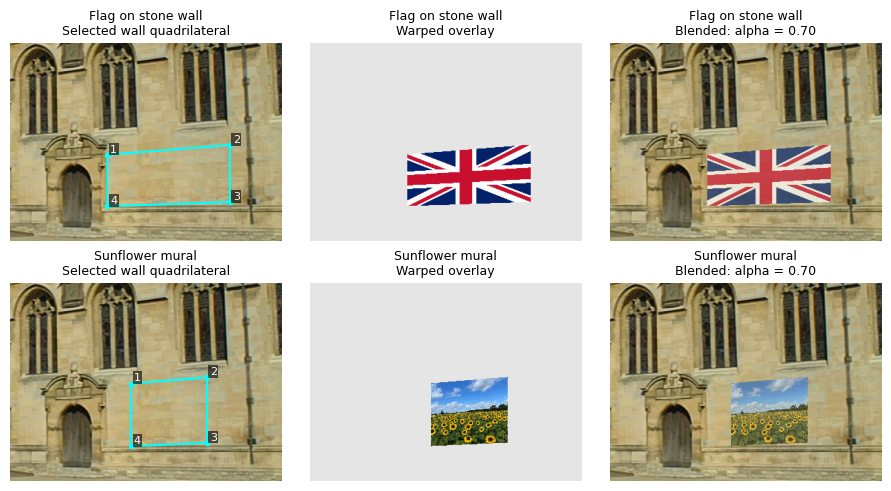

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

q3_image_dir = Path('images')
if not q3_image_dir.is_dir():
    q3_image_dir = Path('Assignment_02/images')
q3_alpha = 0.70
# Image coordinates (column, row), ordered TL, TR, BR, BL.
q3_examples = [
    ('Flag on stone wall', 'wadham.jpg', 'flag.png',
     [[660, 446], [836, 432], [836, 514], [660, 520]]),
    ('Sunflower mural', 'wadham.jpg', 'the_berry_farms_sunflower_field.jpeg',
     [[694, 430], [803, 421], [803, 515], [694, 520]])
]

def q3_load(name):
    image = cv2.imread(str(q3_image_dir/name), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise FileNotFoundError(q3_image_dir/name)
    rgb = cv2.cvtColor(image[..., :3], cv2.COLOR_BGR2RGB).astype(np.float32)/255
    opacity = image[..., 3].astype(np.float32)/255 if image.shape[2] == 4 else np.ones(image.shape[:2], np.float32)
    return rgb, opacity

q3_results = []
q3_fig, q3_axes = plt.subplots(2, 3, figsize=(9, 4.8), constrained_layout=True)
for axes, (name, base_name, overlay_name, coordinates) in zip(q3_axes, q3_examples):
    base, _ = q3_load(base_name)
    overlay, opacity = q3_load(overlay_name)
    height, width = base.shape[:2]
    oh, ow = overlay.shape[:2]
    source = np.float32([[0, 0], [ow-1, 0], [ow-1, oh-1], [0, oh-1]])
    destination = np.float32(coordinates)
    assert cv2.isContourConvex(destination) and cv2.contourArea(destination) > 0
    assert np.all((destination >= 0) & (destination < [width, height]))
    H, _ = cv2.findHomography(source, destination, method=0)
    if H is None or not np.isfinite(H).all() or np.linalg.matrix_rank(H) < 3:
        raise ValueError(f'Invalid homography: {name}')
    mapped = cv2.perspectiveTransform(source[None], H)[0]
    corner_error = float(np.linalg.norm(mapped-destination, axis=1).max())
    assert corner_error < 1e-3

    # Warp premultiplied colour and opacity with identical interpolation.
    # This also supports PNG transparency and avoids dark interpolation edges.
    warped = cv2.warpPerspective(overlay*opacity[..., None], H, (width, height),
                                 flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    mask = cv2.warpPerspective(opacity, H, (width, height), flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT)
    polygon = np.zeros((height, width), np.uint8)
    cv2.fillConvexPoly(polygon, destination.astype(np.int32), 1)
    mask *= polygon
    warped *= polygon[..., None]  # Clip to the rasterized destination polygon.
    blended = np.clip(base*(1-q3_alpha*mask[..., None])+q3_alpha*warped, 0, 1)
    assert np.any(mask > 0) and not np.any((mask > 0) & (polygon == 0))
    assert np.array_equal(blended[polygon == 0], base[polygon == 0])
    assert np.isfinite(blended).all()
    changed = int(np.count_nonzero(np.any(np.abs(blended-base) > 1e-6, axis=2)))
    assert changed > 0
    q3_results.append(dict(name=name, H=H, source=source, destination=destination,
                           base=base, warped=warped, mask=mask, blended=blended,
                           corner_error=corner_error, changed=changed))
    print(f'{name}: base {width}x{height}, overlay {ow}x{oh}, alpha={q3_alpha:.2f}')
    print(f'  TL, TR, BR, BL = {coordinates}; max corner error {corner_error:.2e} px; '
          f'{changed} pixels changed inside the polygon.')

    axes[0].imshow(base)
    axes[0].add_patch(Polygon(destination, closed=True, fill=False,
                               edgecolor='cyan', linewidth=1.5))
    for index, (x, y) in enumerate(destination, 1):
        axes[0].plot(x, y, 'o', color='cyan', markersize=3)
        axes[0].text(x+4, y-4, str(index), color='white', fontsize=8,
                     bbox=dict(facecolor='black', alpha=.6, pad=1, edgecolor='none'))
    # Put the warped overlay on a neutral background, with its opacity mask.
    axes[1].imshow(np.clip(warped+0.9*(1-mask[..., None]), 0, 1))
    axes[2].imshow(blended)
    for ax, title in zip(axes, ['Selected wall quadrilateral', 'Warped overlay', 'Blended: alpha = 0.70']):
        ax.set_title(f'{name}\n{title}', fontsize=9)
        ax.set_xlim(520, 910); ax.set_ylim(570, 285)  # Display crop only.
        ax.axis('off')
plt.show()


### Interpretation and discussion

Both overlays follow the selected wall quadrilaterals. With alpha 0.70, the overlay is clear, but some stone texture still shows through. I used mostly blank wall areas to avoid windows, recesses and occlusions.

The four overlay corners map to the selected wall corners, as expected from a homography computed from four point pairs. The mask keeps the blending inside the selected quadrilateral, so the rest of the image is unchanged.

This method works well when the destination is approximately planar. It can look less realistic if the selected points are inaccurate, the wall is not flat, the lighting does not match, or shadows and surface texture are not modeled.
